# FORGE — Wearable EEG Benchmark

**Part 1 (§1–7): the CHB-MIT electrode-reduction benchmark.**
**Part 2 (§8–12): the exploratory seizure-type and anatomical-onset analysis on
SeizeIT2, plus the harmonised schema and the TUH-ready adapter.**

This notebook reads the artefacts produced by the scripts in `scripts/`; it does
not recompute them. To regenerate everything from scratch:

```
python scripts/01_inventory.py
python scripts/02_download.py
python scripts/04_extract_and_prune.py --keep chb01
python scripts/06_experiments.py main
python scripts/06_experiments.py random
python scripts/07_report.py
python scripts/05_figures.py explore && python scripts/05_figures.py results
```

**What is being compared.** CHB-MIT channels such as `F7-T7` are *bipolar
differences between two electrodes*. A four-contact wearable mock-up gives two
bipolar channels; a two-contact one gives a single channel. These are
scalp-position proxies, not recordings from real glasses or earbuds.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from seizure_eeg.config import (DATA_ROOT, FIGURES_DIR, MONTAGES,
                                MONTAGE_CONTACTS, TABLES_DIR)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
print("repo:", ROOT)

repo: /home/user/forge_seizure_eeg


## 1. What is in the dataset

Parsed from the per-subject `chbXX-summary.txt` files, not inferred from
filenames. chb01 and chb21 are the **same person**, so the 24 cases are 23
people — they are kept in one cross-validation group.

In [2]:
inv = pd.read_csv(TABLES_DIR / "subject_inventory.csv")
print(f"{len(inv)} cases, {inv.n_seizures.sum()} annotated seizures, "
      f"{inv.ictal_seconds.sum()/3600:.1f} ictal hours")
display(inv[["case", "n_files_in_summary", "n_seizure_files", "n_seizures",
             "ictal_seconds"]].head(24))

24 cases, 198 annotated seizures, 3.2 ictal hours


,case,n_files_in_summary,n_seizure_files,n_seizures,ictal_seconds
0,chb01,42,7,7,442
1,chb02,36,3,3,172
2,chb03,38,7,7,402
3,chb04,42,3,4,378
4,chb05,39,5,5,558
5,chb06,18,7,10,153
6,chb07,19,3,3,325
7,chb08,20,5,5,919
8,chb09,19,3,4,276
9,chb10,25,7,7,447


## 2. The electrode configurations

Every configuration below is a list of **bipolar derivations**, with the
physical contacts each one would need.

In [3]:
rows = [{"configuration": m, "contacts": len(MONTAGE_CONTACTS[m]),
         "which contacts": ", ".join(MONTAGE_CONTACTS[m]),
         "bipolar channels": len(MONTAGES[m]),
         "derivations": ", ".join(MONTAGES[m])}
        for m in MONTAGES]
display(pd.DataFrame(rows))

,configuration,contacts,which contacts,bipolar channels,derivations
0,full_18_bipolar,19,"C3, C4, CZ, F3, F4, F7, F8, FP1, FP2, FZ, O1, ...",18,"FP1-F7, F7-T7, T7-P7, P7-O1, FP1-F3, F3-C3, C3..."
1,glasses_4_contacts,4,"F7, F8, FP1, FP2",2,"FP1-F7, FP2-F8"
2,temporal_4_contacts,4,"F7, F8, T7, T8",2,"F7-T7, F8-T8"
3,posterior_temporal_4_contacts,4,"P7, P8, T7, T8",2,"T7-P7, T8-P8"
4,lower_temporal_4_contacts,4,"FT10, FT9, T7, T8",2,"T7-FT9, FT10-T8"
5,left_temporal_2_contacts,2,"F7, T7",1,F7-T7
6,right_temporal_2_contacts,2,"F8, T8",1,F8-T8


## 3. Features from one recording

Features are computed **once for the union of every montage's channels**, so a
montage's design matrix is a column slice. That makes the comparison paired by
construction: identical recordings, identical windows, identical labels.

In [4]:
from seizure_eeg.dataset import (UNION_CHANNELS, available_montages,
                                 extract_recording, montage_matrix)
from seizure_eeg.summary import parse_summary

edf = DATA_ROOT / "chb01" / "chb01_03.edf"
if edf.exists():
    intervals = parse_summary(DATA_ROOT / "chb01" / "chb01-summary.txt")["chb01_03.edf"]
    X, Q, meta = extract_recording(edf, intervals)
    print("seizure intervals:", intervals)
    print("feature tensor (windows, channels, features):", X.shape)
    print("montages available in this recording:", available_montages(Q))
    for m in ["full_18_bipolar", "temporal_4_contacts", "left_temporal_2_contacts"]:
        d, usable, names = montage_matrix(X, Q, m)
        print(f"  {m:30s} design {d.shape}, usable windows {usable.sum()}")
    display(meta[meta.label == 1][["start_s", "stop_s", "ictal_overlap_s",
                                   "seizure_idx", "label"]])
else:
    print("raw chb01 EDFs not present - run scripts/02_download.py --cases chb01")

seizure intervals: [(2996, 3036)]
feature tensor (windows, channels, features): (360, 20, 14)
montages available in this recording: ['full_18_bipolar', 'glasses_4_contacts', 'temporal_4_contacts', 'posterior_temporal_4_contacts', 'lower_temporal_4_contacts', 'left_temporal_2_contacts', 'right_temporal_2_contacts']
  full_18_bipolar                design (360, 252), usable windows 360
  temporal_4_contacts            design (360, 28), usable windows 360
  left_temporal_2_contacts       design (360, 14), usable windows 360


,start_s,stop_s,ictal_overlap_s,seizure_idx,label
299,2990.0,3000.0,4.0,0,1
300,3000.0,3010.0,10.0,0,1
301,3010.0,3020.0,10.0,0,1
302,3020.0,3030.0,10.0,0,1
303,3030.0,3040.0,6.0,0,1


## 4. The same seizure through each electrode set

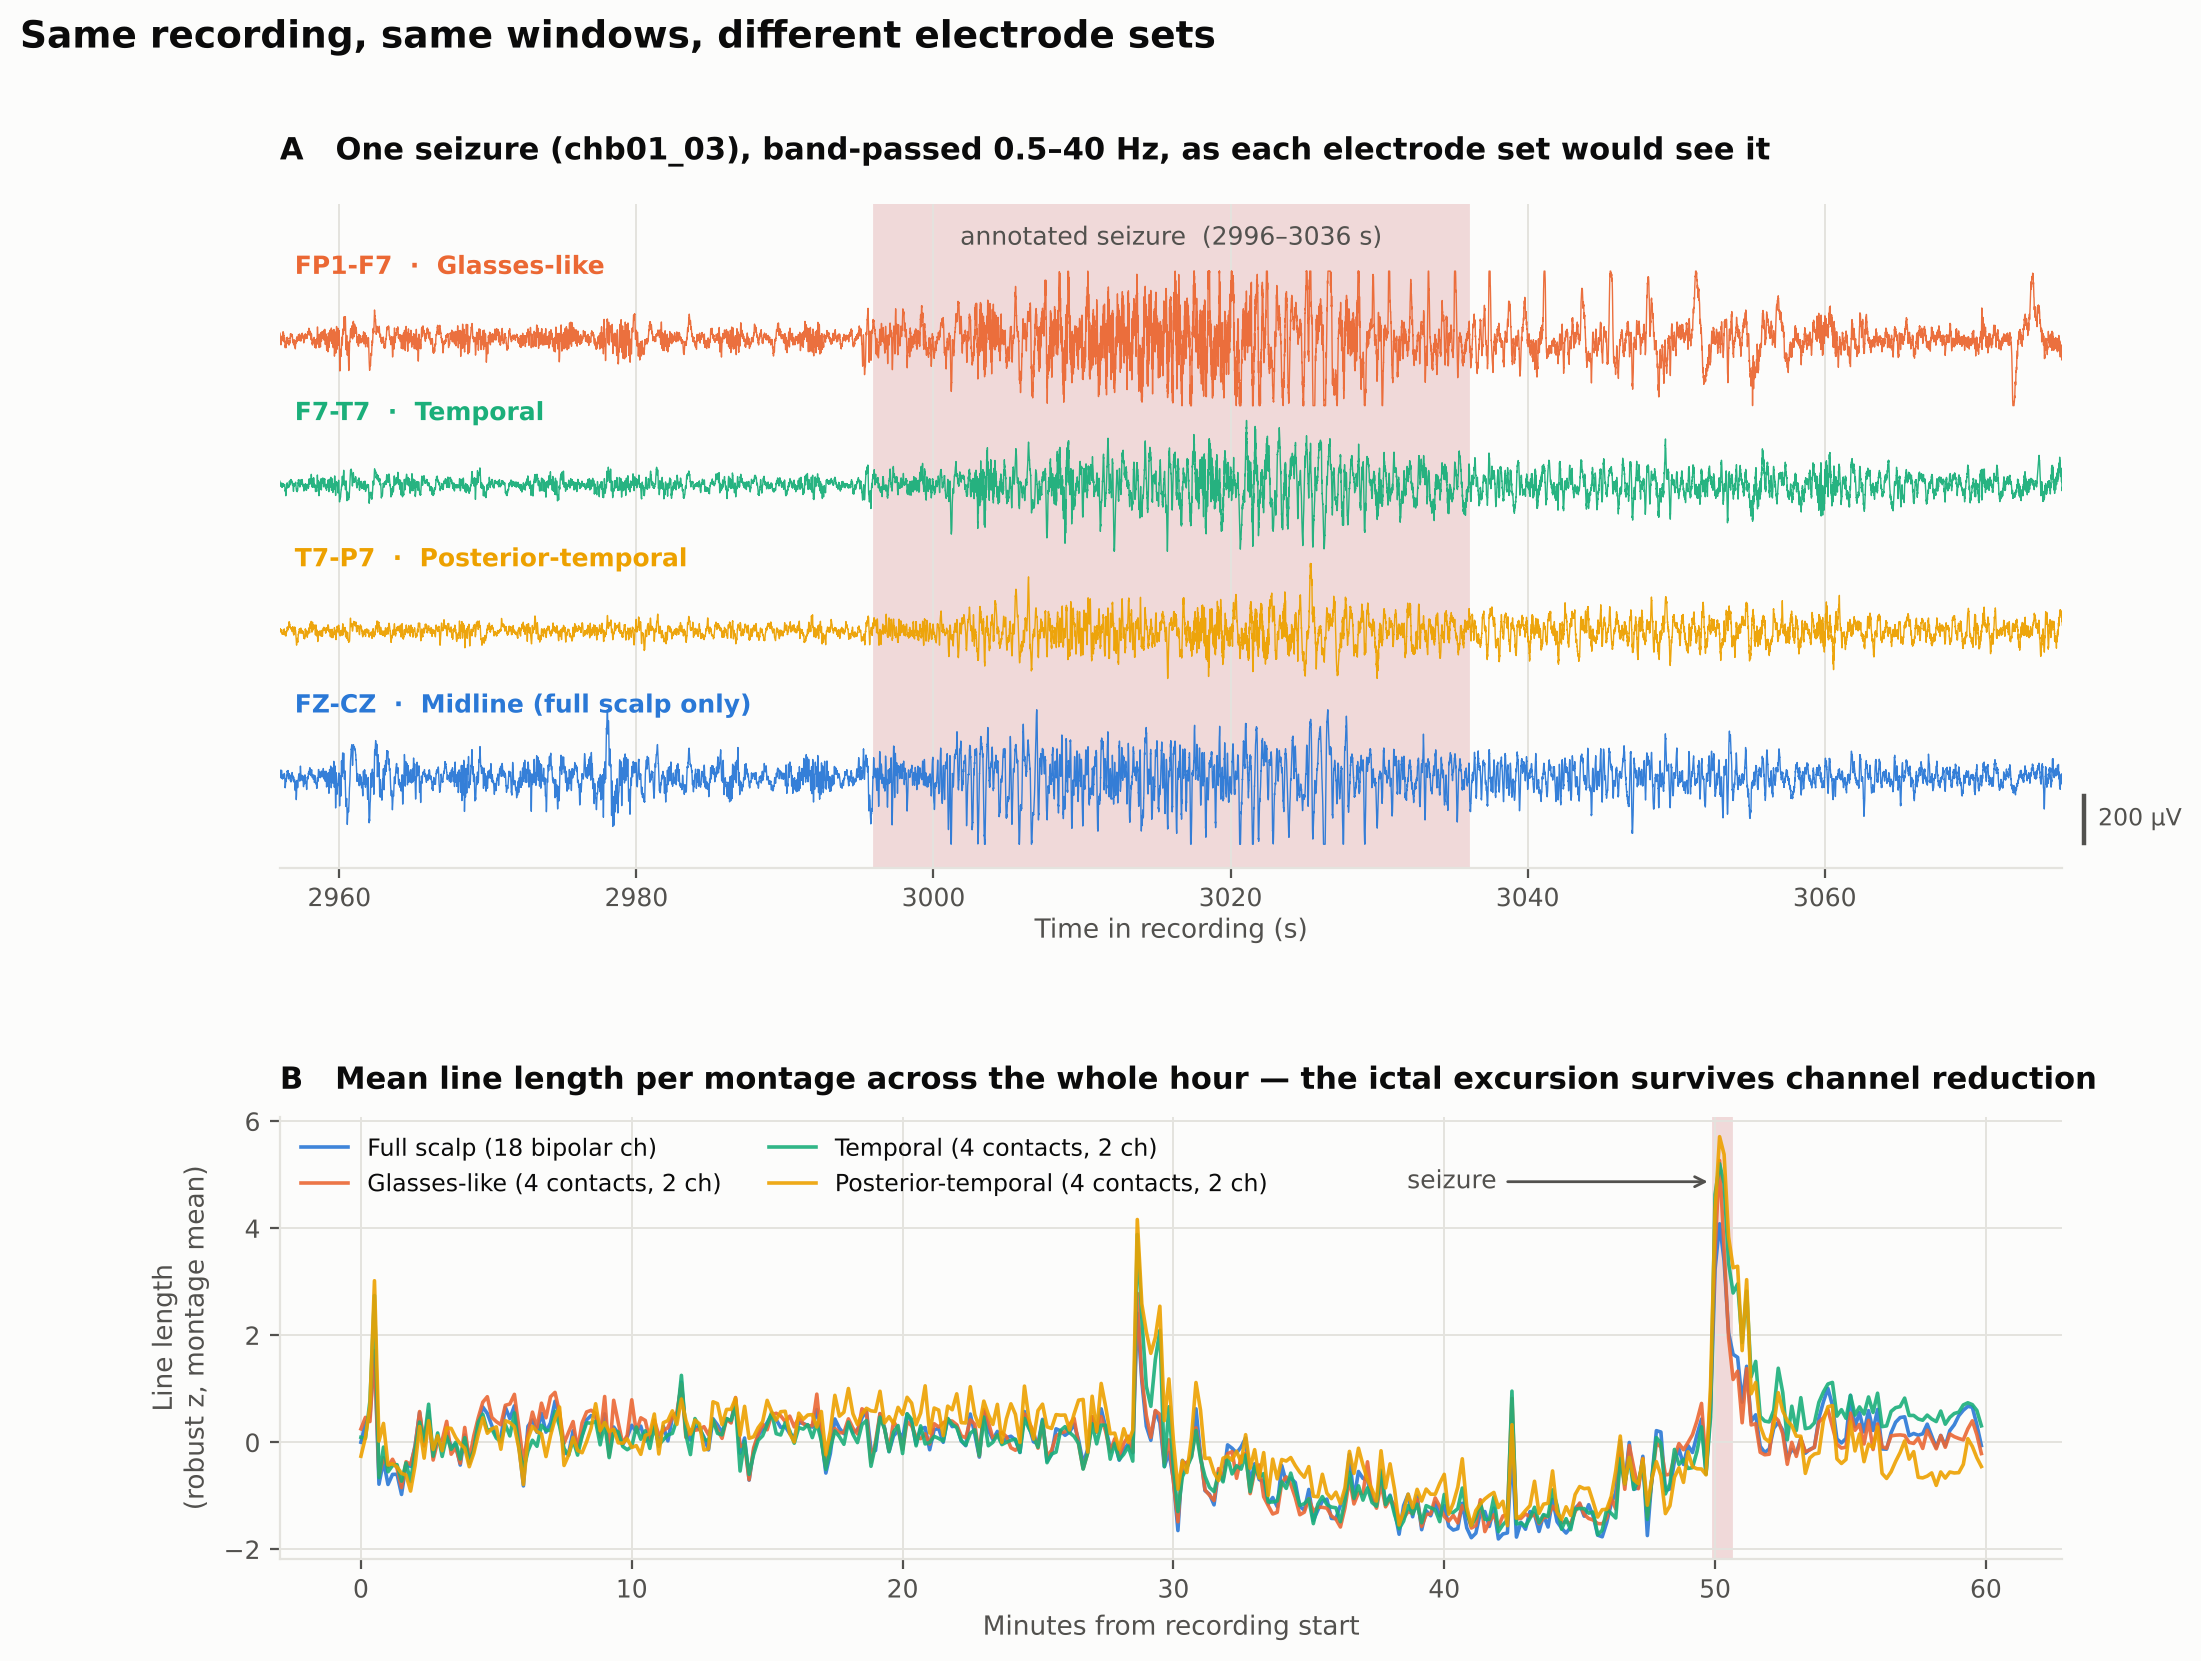

In [5]:
display(Image(filename=str(FIGURES_DIR / "fig1_exploratory_montages.png")))

## 5. Patient-disjoint benchmark

Shrinkage LDA, 5-fold `GroupKFold` over patients. Decision thresholds are fitted
on out-of-fold scores from the **training** patients and applied unchanged to
the held-out patients. Confidence intervals are percentile bootstraps over
patients.

In [6]:
sys.path.insert(0, str(ROOT / "scripts"))
from importlib import import_module
report = import_module("07_report")

folds = pd.read_csv(TABLES_DIR / "cv_folds_main.csv")
patients = pd.read_csv(TABLES_DIR / "cv_patients_main.csv")
summary = report.summary_table(patients, folds, target=6.0)
display(Markdown(report.to_markdown(summary, 6.0)))

| Configuration | Contacts | Bipolar ch | AUPRC [95% CI] | Seizure sensitivity @ 6 FA/h target | Achieved FA/h | Median latency | Seizures detected |
|---|---:|---:|---|---|---:|---:|---:|
| Full scalp (18 bipolar ch) | 19 | 18 | 0.209 [0.113–0.318] | 0.80 [0.68–0.90] | 9.6 | 18 s | 142/198 |
| Glasses-like (4 contacts, 2 ch) | 4 | 2 | 0.133 [0.069–0.211] | 0.73 [0.60–0.85] | 5.7 | 28 s | 118/198 |
| Temporal (4 contacts, 2 ch) | 4 | 2 | 0.170 [0.091–0.272] | 0.81 [0.68–0.92] | 5.3 | 20 s | 136/198 |
| Posterior-temporal (4 contacts, 2 ch) | 4 | 2 | 0.195 [0.112–0.301] | 0.80 [0.67–0.92] | 5.3 | 21 s | 142/198 |
| Left temporal (2 contacts, 1 ch) | 2 | 1 | 0.198 [0.114–0.299] | 0.78 [0.65–0.90] | 5.7 | 23 s | 134/198 |
| Right temporal (2 contacts, 1 ch) | 2 | 1 | 0.119 [0.068–0.181] | 0.77 [0.64–0.89] | 5.9 | 27 s | 138/198 |


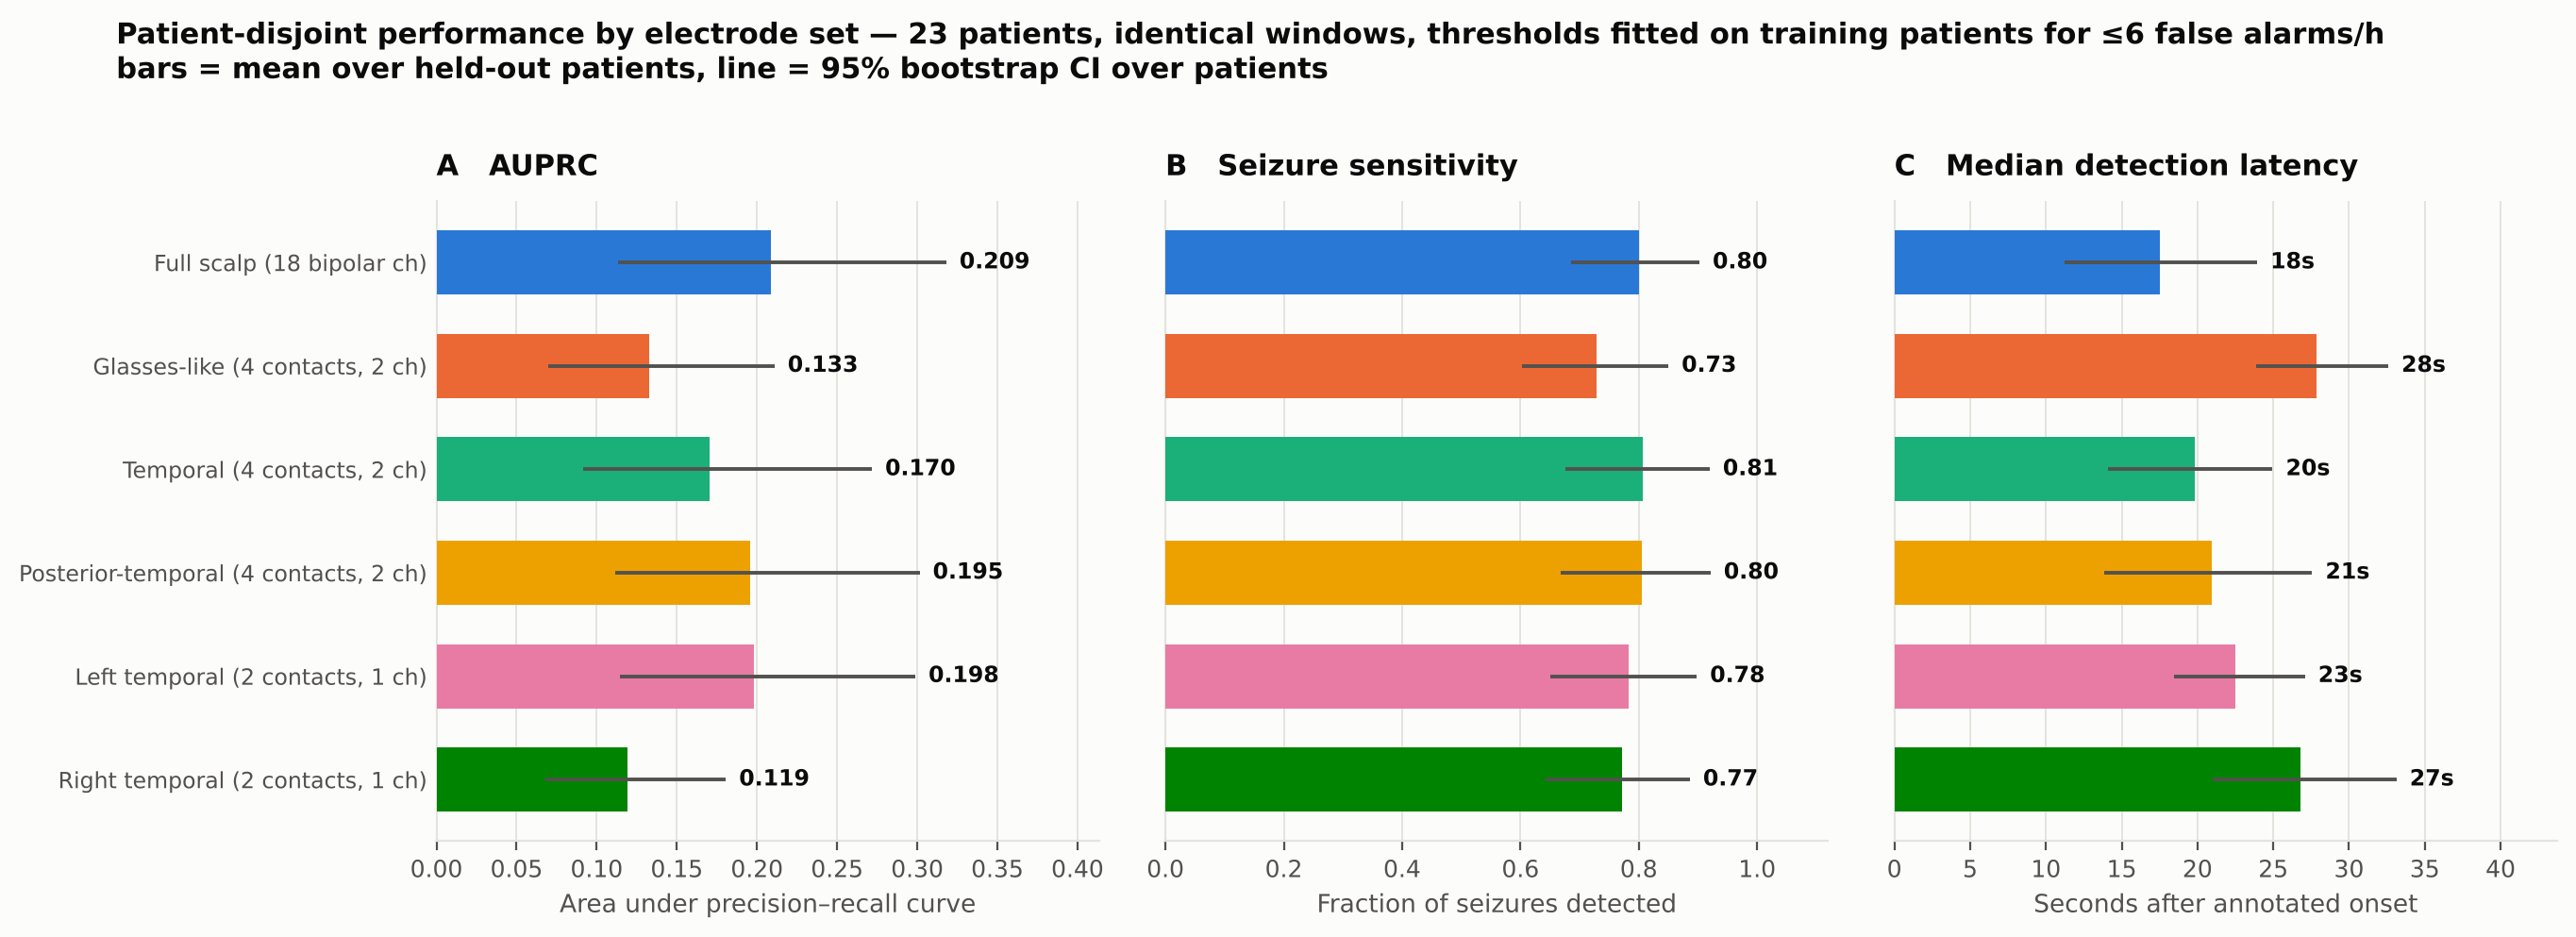

In [7]:
display(Image(filename=str(FIGURES_DIR / "fig2_montage_performance.png")))

### Does the trade-off hold at other alarm budgets?

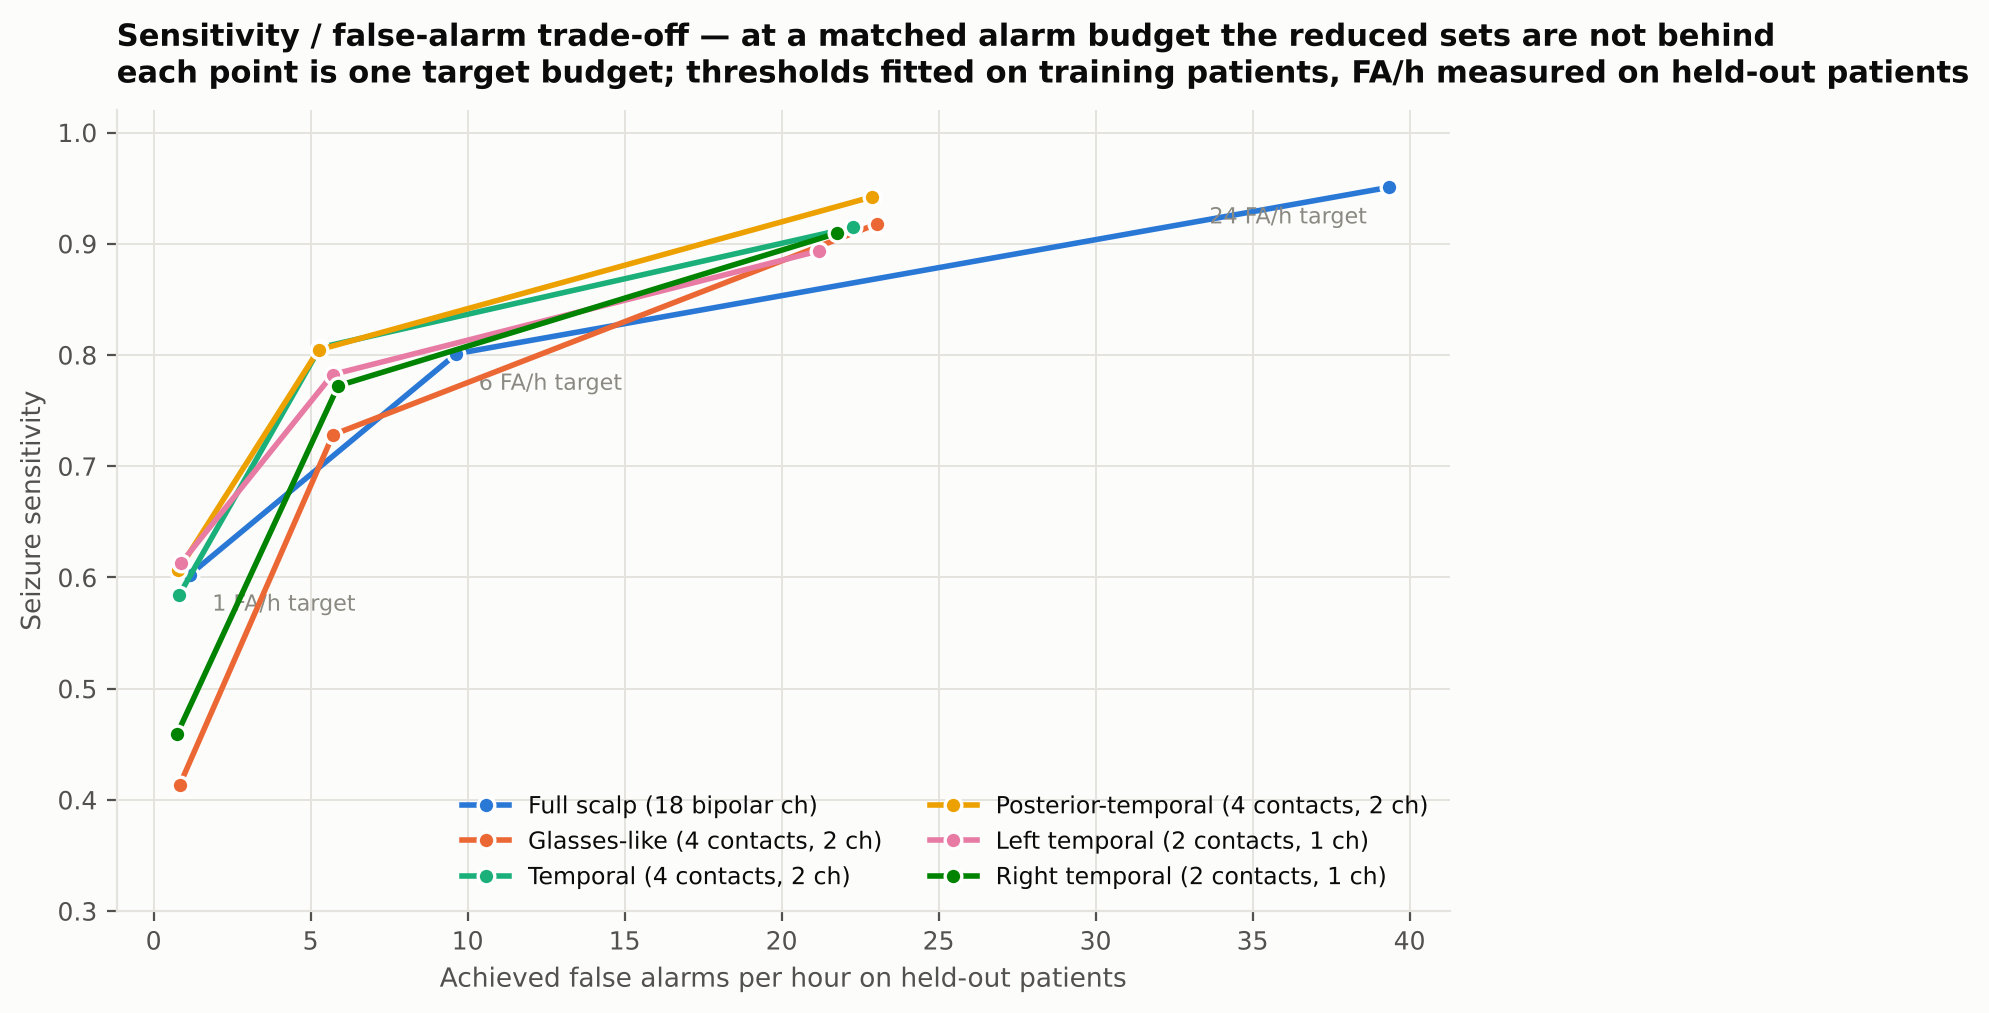

In [8]:
display(Image(filename=str(FIGURES_DIR / "fig3_sensitivity_vs_false_alarms.png")))

### Paired per-patient differences against the full montage

A paired comparison is the honest one here: the same patients, the same windows,
one configuration against another.

In [9]:
d = report.paired_delta(patients, "auprc", 6.0)
display(d[["montage", "n_patients", "mean_delta", "ci_lo", "ci_hi",
           "n_better", "n_worse"]])

,montage,n_patients,mean_delta,ci_lo,ci_hi,n_better,n_worse
0,glasses_4_contacts,23,-0.075976,-0.154255,-0.002378,9,14
1,left_temporal_2_contacts,23,-0.010677,-0.068668,0.045381,11,12
2,posterior_temporal_4_contacts,23,-0.013493,-0.068819,0.036164,14,9
3,right_temporal_2_contacts,23,-0.089912,-0.172272,-0.014813,7,16
4,temporal_4_contacts,23,-0.038551,-0.102015,0.018760,11,12


## 6. Placement control

Every 2-channel subset of the standard 18 derivations, scored the same way. This
puts the wearable-plausible placements on a percentile instead of comparing them
only to each other.

153 channel pairs evaluated


,channels,contacts,auprc,auprc_sd,auroc
0,T7-P7+FZ-CZ,CZ+FZ+P7+T7,0.212648,0.104019,0.814892
1,T7-P7+P7-O1,O1+P7+T7,0.198905,0.096613,0.807047
2,F7-T7+FZ-CZ,CZ+F7+FZ+T7,0.196586,0.122199,0.811380
3,F7-T7+P4-O2,F7+O2+P4+T7,0.192137,0.117892,0.806106
4,F7-T7+P7-O1,F7+O1+P7+T7,0.191873,0.093371,0.817918
5,T7-P7+CZ-PZ,CZ+P7+PZ+T7,0.191197,0.071603,0.824142
6,P7-O1+FZ-CZ,CZ+FZ+O1+P7,0.188860,0.100552,0.830742
7,T7-P7+P3-O1,O1+P3+P7+T7,0.188032,0.093649,0.799271
8,F7-T7+P8-O2,F7+O2+P8+T7,0.187622,0.106254,0.816913
9,F7-T7+T8-P8,F7+P8+T7+T8,0.186721,0.112152,0.826447


Temporal             AUPRC 0.130 - 55th percentile
Glasses-like         AUPRC 0.090 - 14th percentile
Posterior-temporal   AUPRC 0.169 - 88th percentile


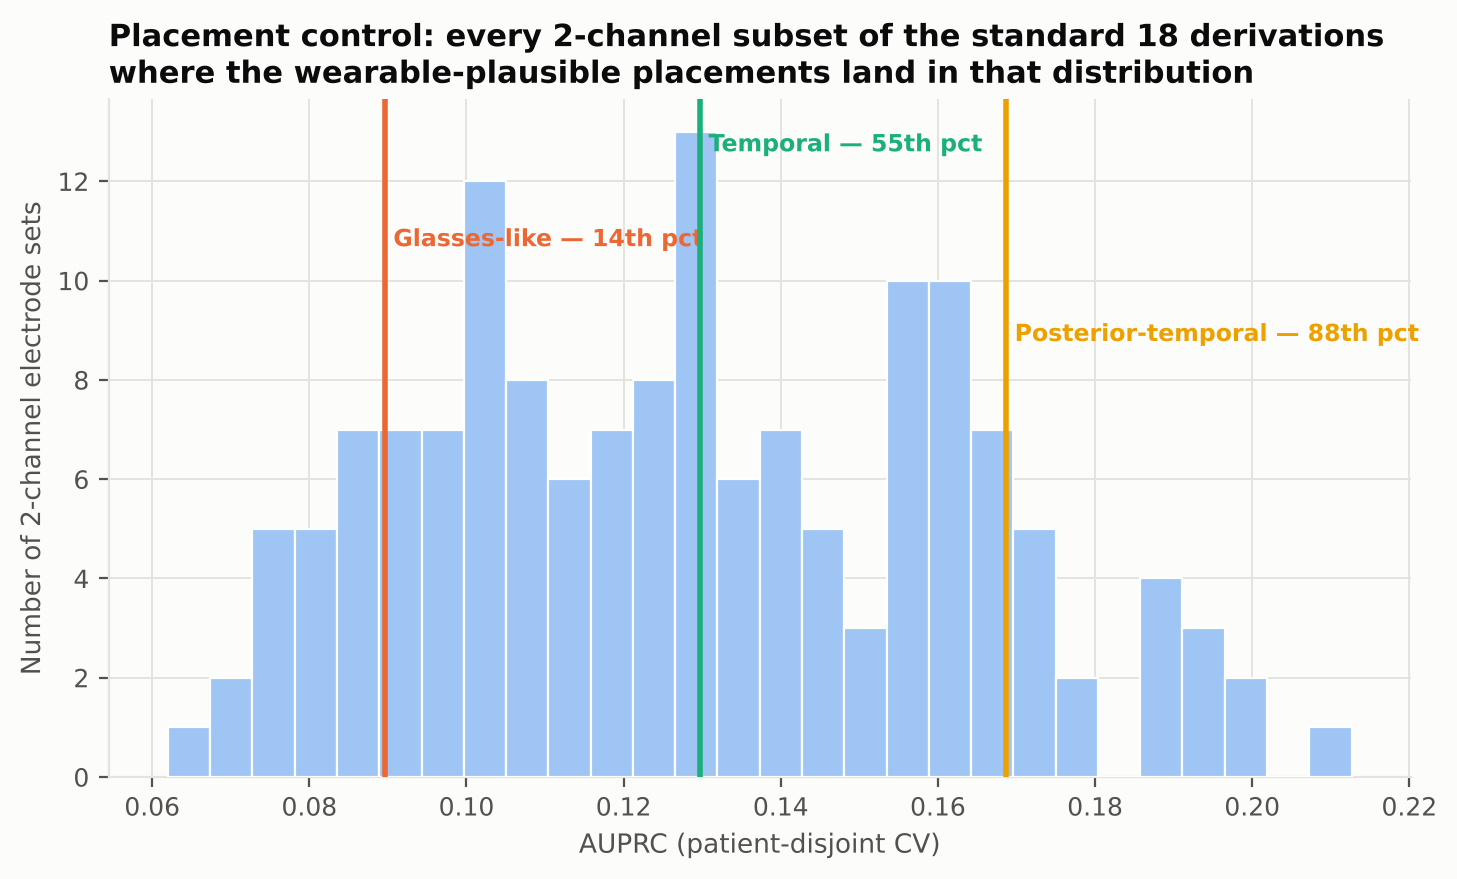

In [10]:
ctrl_path = TABLES_DIR / "random_pair_control.csv"
if ctrl_path.exists():
    ctrl = pd.read_csv(ctrl_path)
    print(f"{len(ctrl)} channel pairs evaluated")
    display(ctrl.head(10))
    for name, key in [("Temporal", "F7-T7+F8-T8"),
                      ("Glasses-like", "FP1-F7+FP2-F8"),
                      ("Posterior-temporal", "T7-P7+T8-P8")]:
        row = ctrl[ctrl.channels == key]
        if not row.empty:
            v = float(row.auprc.iloc[0])
            print(f"{name:20s} AUPRC {v:.3f} - {100*(ctrl.auprc < v).mean():.0f}th percentile")
    display(Image(filename=str(FIGURES_DIR / "fig4_placement_control.png")))
else:
    print("run: python scripts/06_experiments.py random")

## 7. Per-patient variability

The spread between patients is much larger than the spread between electrode
sets — which is the main practical message for a wearable.

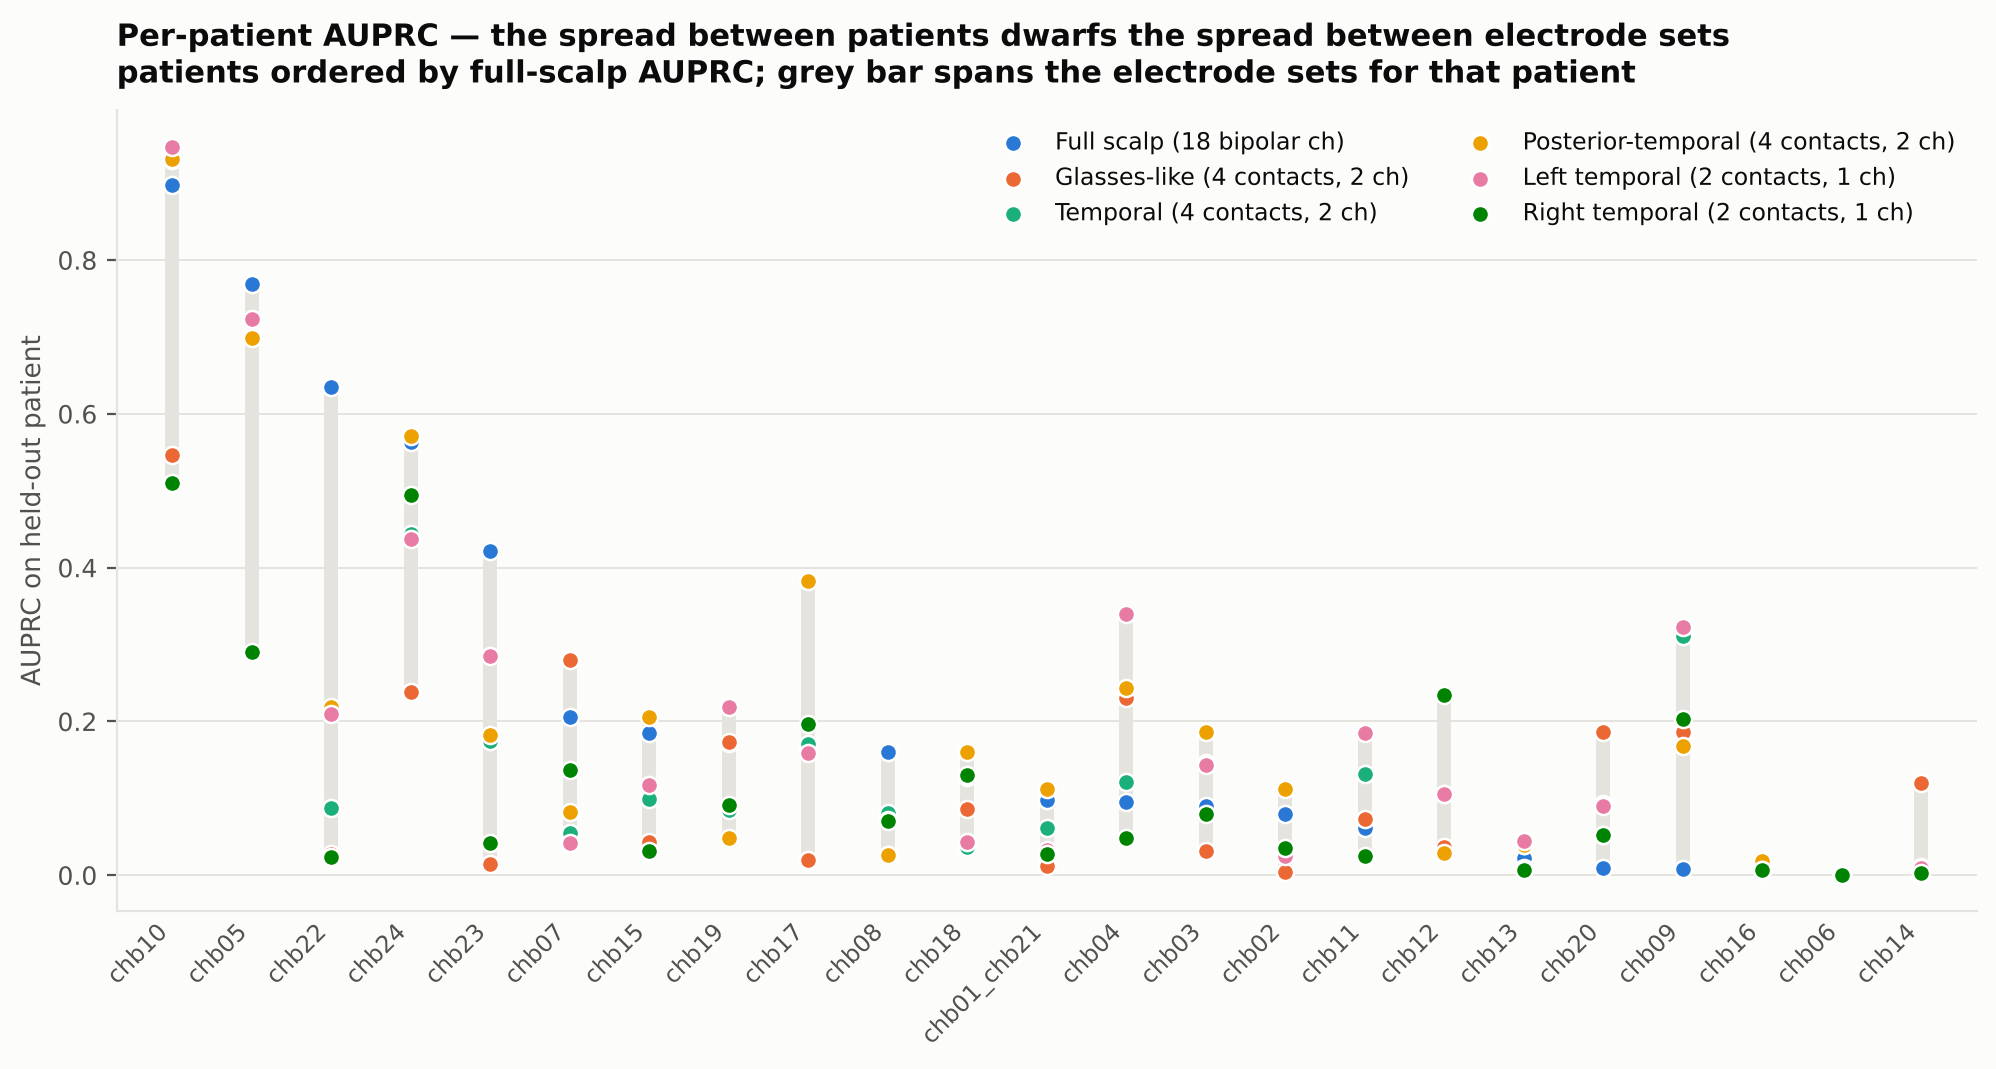

montage,full_18_bipolar,glasses_4_contacts,left_temporal_2_contacts,posterior_temporal_4_contacts,right_temporal_2_contacts,temporal_4_contacts
patient_id,,,,,,
chb01_chb21,0.098,0.012,0.032,0.112,0.028,0.062
chb02,0.079,0.005,0.025,0.113,0.035,0.029
chb03,0.090,0.032,0.143,0.186,0.079,0.146
chb04,0.095,0.231,0.340,0.243,0.048,0.121
chb05,0.768,0.705,0.723,0.698,0.291,0.701
chb06,0.002,0.001,0.001,0.001,0.001,0.001
chb07,0.206,0.280,0.042,0.082,0.137,0.054
chb08,0.160,0.026,0.071,0.027,0.071,0.081
chb09,0.008,0.186,0.323,0.168,0.203,0.311


In [11]:
display(Image(filename=str(FIGURES_DIR / "fig5_per_patient.png")))
pp = (patients[patients.target_fa_per_h == 6.0]
      .pivot_table(index="patient_id", columns="montage", values="auprc"))
display(pp.round(3))

## Caveats

* CHB-MIT is paediatric, single-centre, and these are **scalp-position proxies**
  for wearables, not real device recordings.
* The task is ictal vs non-ictal classification, not seizure prediction.
* CHB-MIT has no seizure-onset-localisation labels, so the "are around-ear
  contacts better for temporal-lobe seizures?" question needs SeizeIT2.
* SeizeIT2's public release has behind-the-ear wearable signals and clinical
  annotations but **no paired full-scalp EEG**, so it supports external
  validation, not a same-recording electrode ablation.

---

# Part 2 — Seizure type and anatomical onset

Everything below uses **SeizeIT2** (OpenNeuro `ds005873`): real behind-the-ear
wearable EEG from 125 patients with focal epilepsy, with clinical annotations
for seizure subtype, onset lobe, hemisphere and vigilance.

**These are not interchangeable with Part 1.** CHB-MIT gives *scalp-position
proxies* for a wearable; SeizeIT2 gives a *real* two-channel around-ear device
with no paired full-scalp recording. The two are never plotted on shared axes,
and no full-versus-wearable claim is made from SeizeIT2.

## 8. The harmonised dataset layer

One schema spans all three corpora, so a subgroup analysis is written once.

In [12]:
from seizure_eeg.datasets.chbmit import CHBMITAdapter
from seizure_eeg.datasets.seizeit2 import SeizeIT2Adapter
from seizure_eeg.datasets.tuh import TUSZAdapter, mapping_plan_frame

adapters = {
    "CHB-MIT (scalp proxy)": CHBMITAdapter(ROOT / "data" / "chbmit"),
    "SeizeIT2 (real wearable)": SeizeIT2Adapter(ROOT / "data" / "seizeit2"),
    "TUSZ (planned)": TUSZAdapter(ROOT / "data" / "tusz"),
}
avail = pd.DataFrame({name: ad.label_availability()
                      for name, ad in adapters.items()})
display(Markdown("**Which clinical labels each dataset actually carries**"))
display(avail)
display(Markdown(
    "`not_annotated` means the dataset has no such field. It is never filled "
    "in by inferring anatomy from the signal - that would manufacture a "
    "clinical label and make the subgroup analysis circular."))

**Which clinical labels each dataset actually carries**

,CHB-MIT (scalp proxy),SeizeIT2 (real wearable),TUSZ (planned)
seizure_type,not_annotated,annotated,annotated
onset_lobe,not_annotated,annotated,not_annotated
onset_hemisphere,not_annotated,annotated,not_annotated
vigilance,not_annotated,annotated,not_annotated
channel_level_annotation,not_annotated,not_annotated,annotated
paired_full_scalp_eeg,annotated,not_annotated,annotated


`not_annotated` means the dataset has no such field. It is never filled in by inferring anatomy from the signal - that would manufacture a clinical label and make the subgroup analysis circular.

## 9. SeizeIT2 annotation inventory

Parsed straight from the BIDS `*_events.tsv` files. Multilobar and unknown
onsets are kept as their own categories rather than folded into one lobe.

In [13]:
ev2 = pd.read_csv(TABLES_DIR / "seizeit2_events_harmonised.csv")
print(f"{len(ev2)} seizures, {ev2.patient_id.nunique()} patients, "
      f"{ev2.recording_id.nunique()} recordings, "
      f"{ev2.duration_s.sum()/3600:.1f} ictal hours")
for col in ["seizure_type", "onset_lobe", "onset_hemisphere", "vigilance"]:
    g = (ev2.groupby(col)
         .agg(seizures=("event_index", "size"),
              patients=("patient_id", "nunique"))
         .sort_values("seizures", ascending=False))
    display(Markdown(f"**by `{col}`**"))
    display(g)

883 seizures, 125 patients, 395 recordings, 14.3 ictal hours


**by `seizure_type`**

,seizures,patients
seizure_type,,
focal_impaired_awareness,391,74
focal_aware,316,34
focal_unknown_awareness,115,26
focal_to_bilateral_tonic_clonic,55,37
unknown_onset,6,2


**by `onset_lobe`**

,seizures,patients
onset_lobe,,
temporal,264,68
unknown,231,36
multilobar,181,32
frontal,160,19
insular,18,2
occipital,17,5
central,11,1
parietal,1,1


**by `onset_hemisphere`**

,seizures,patients
onset_hemisphere,,
left,386,71
unknown,376,43
right,112,47
bilateral,9,7


**by `vigilance`**

,seizures,patients
vigilance,,
awake,426,95
asleep,367,53
unknown,90,21


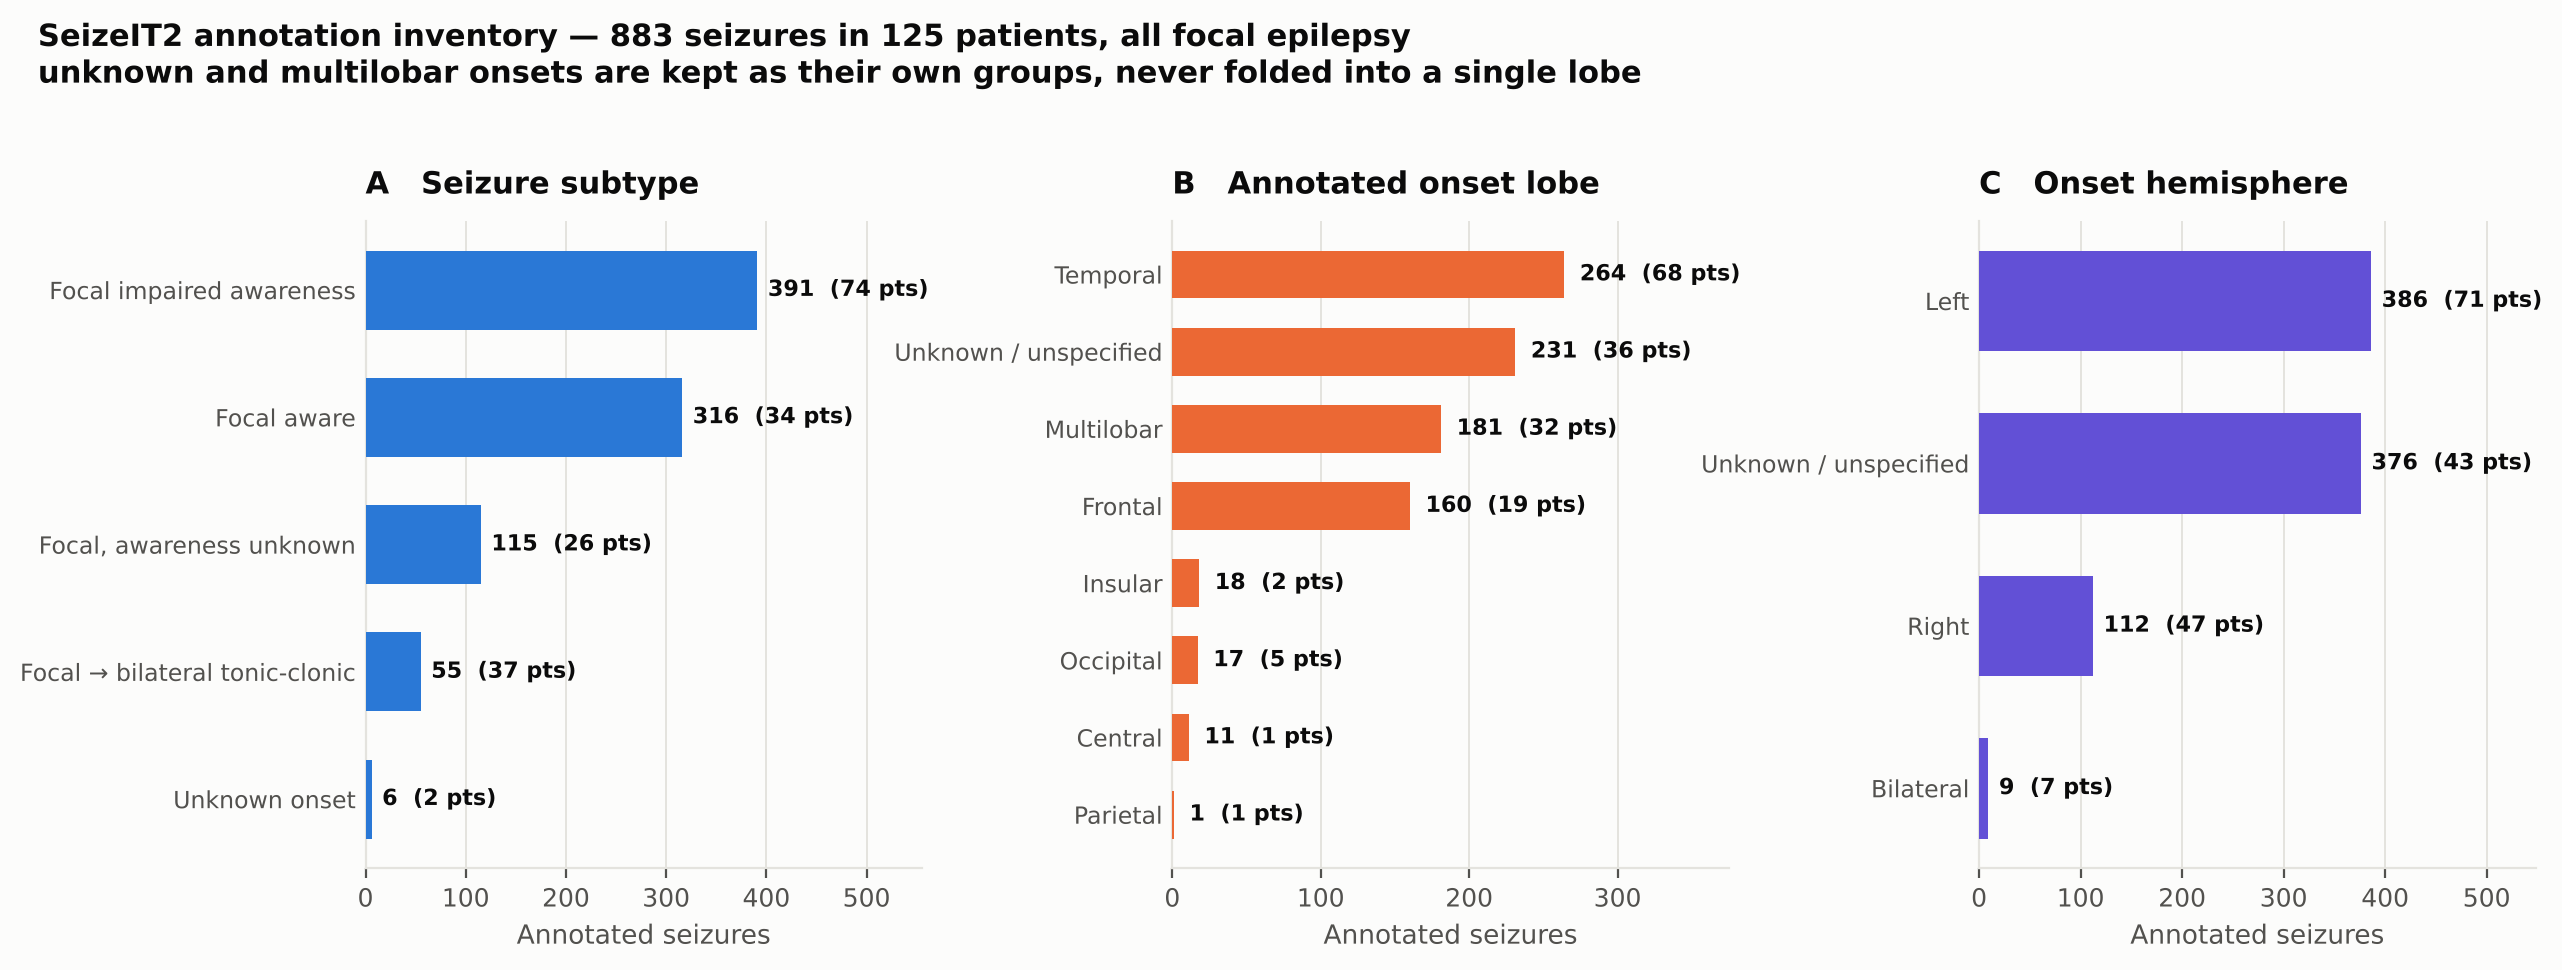

In [14]:
display(Image(filename=str(FIGURES_DIR / "fig8_seizeit2_annotation_inventory.png")))

### How the raw ILAE codes are harmonised

`sz_foc_a` (focal aware) and `sz_foc_ia` (focal impaired awareness) share a
string prefix, so matching is on complete underscore segments, not prefixes.

In [15]:
from seizure_eeg.datasets.seizeit2 import (harmonise_localization,
                                            harmonise_seizure_type)

display(pd.DataFrame(
    [{"raw eventType": c, "harmonised": harmonise_seizure_type(c)}
     for c in ["sz_foc_a", "sz_foc_a_m_automatisms", "sz_foc_ia",
               "sz_foc_ia_nm_behavior", "sz_foc_ua_m", "sz_foc_f2b",
               "sz_gen_m_tonicClonic", "sz_uo", "sz"]]))
display(pd.DataFrame(
    [{"raw localization": c, "onset_lobe": harmonise_localization(c)[0],
      "all lobes": ", ".join(harmonise_localization(c)[1]) or "-"}
     for c in ["temp", "front", "front_temp", "front_cen_temp",
               "temp_par_occ", "ins", "un"]]))

,raw eventType,harmonised
0,sz_foc_a,focal_aware
1,sz_foc_a_m_automatisms,focal_aware
2,sz_foc_ia,focal_impaired_awareness
3,sz_foc_ia_nm_behavior,focal_impaired_awareness
4,sz_foc_ua_m,focal_unknown_awareness
5,sz_foc_f2b,focal_to_bilateral_tonic_clonic
6,sz_gen_m_tonicClonic,generalized
7,sz_uo,unknown_onset
8,sz,unclassified


,raw localization,onset_lobe,all lobes
0,temp,temporal,temporal
1,front,frontal,frontal
2,front_temp,multilobar,"frontal, temporal"
3,front_cen_temp,multilobar,"frontal, central, temporal"
4,temp_par_occ,multilobar,"temporal, parietal, occipital"
5,ins,insular,insular
6,un,unknown,-


## 10. Detection on real wearable EEG, by seizure subtype

Same pipeline as Part 1: 10 s windows, same feature set, shrinkage LDA,
patient-disjoint 5-fold CV, thresholds fitted on training patients only.

506/883 seizures detected (57.3%) at the 6 FA/h target; median latency 23 s; mean AUPRC 0.042 (prevalence 0.0054)


,target_fa_per_h,seizure_type,n_seizures,n_patients,n_detected,sensitivity,sensitivity_lo,sensitivity_hi,median_latency_s,latency_lo,latency_hi,median_duration_s,n_detected_with_latency
0,6.0,focal_impaired_awareness,391,74,235,0.601,0.435,0.761,22.0,19.0,25.0,33.0,235
1,6.0,focal_aware,316,34,172,0.544,0.349,0.722,23.0,15.0,29.0,32.0,172
2,6.0,focal_unknown_awareness,115,26,41,0.357,0.271,0.507,24.0,18.0,41.0,14.0,41
3,6.0,focal_to_bilateral_tonic_clonic,55,37,54,0.982,0.936,1.000,30.0,25.0,33.0,108.0,54
4,6.0,unknown_onset,6,2,4,0.667,0.000,0.800,17.0,17.0,17.0,10.5,4


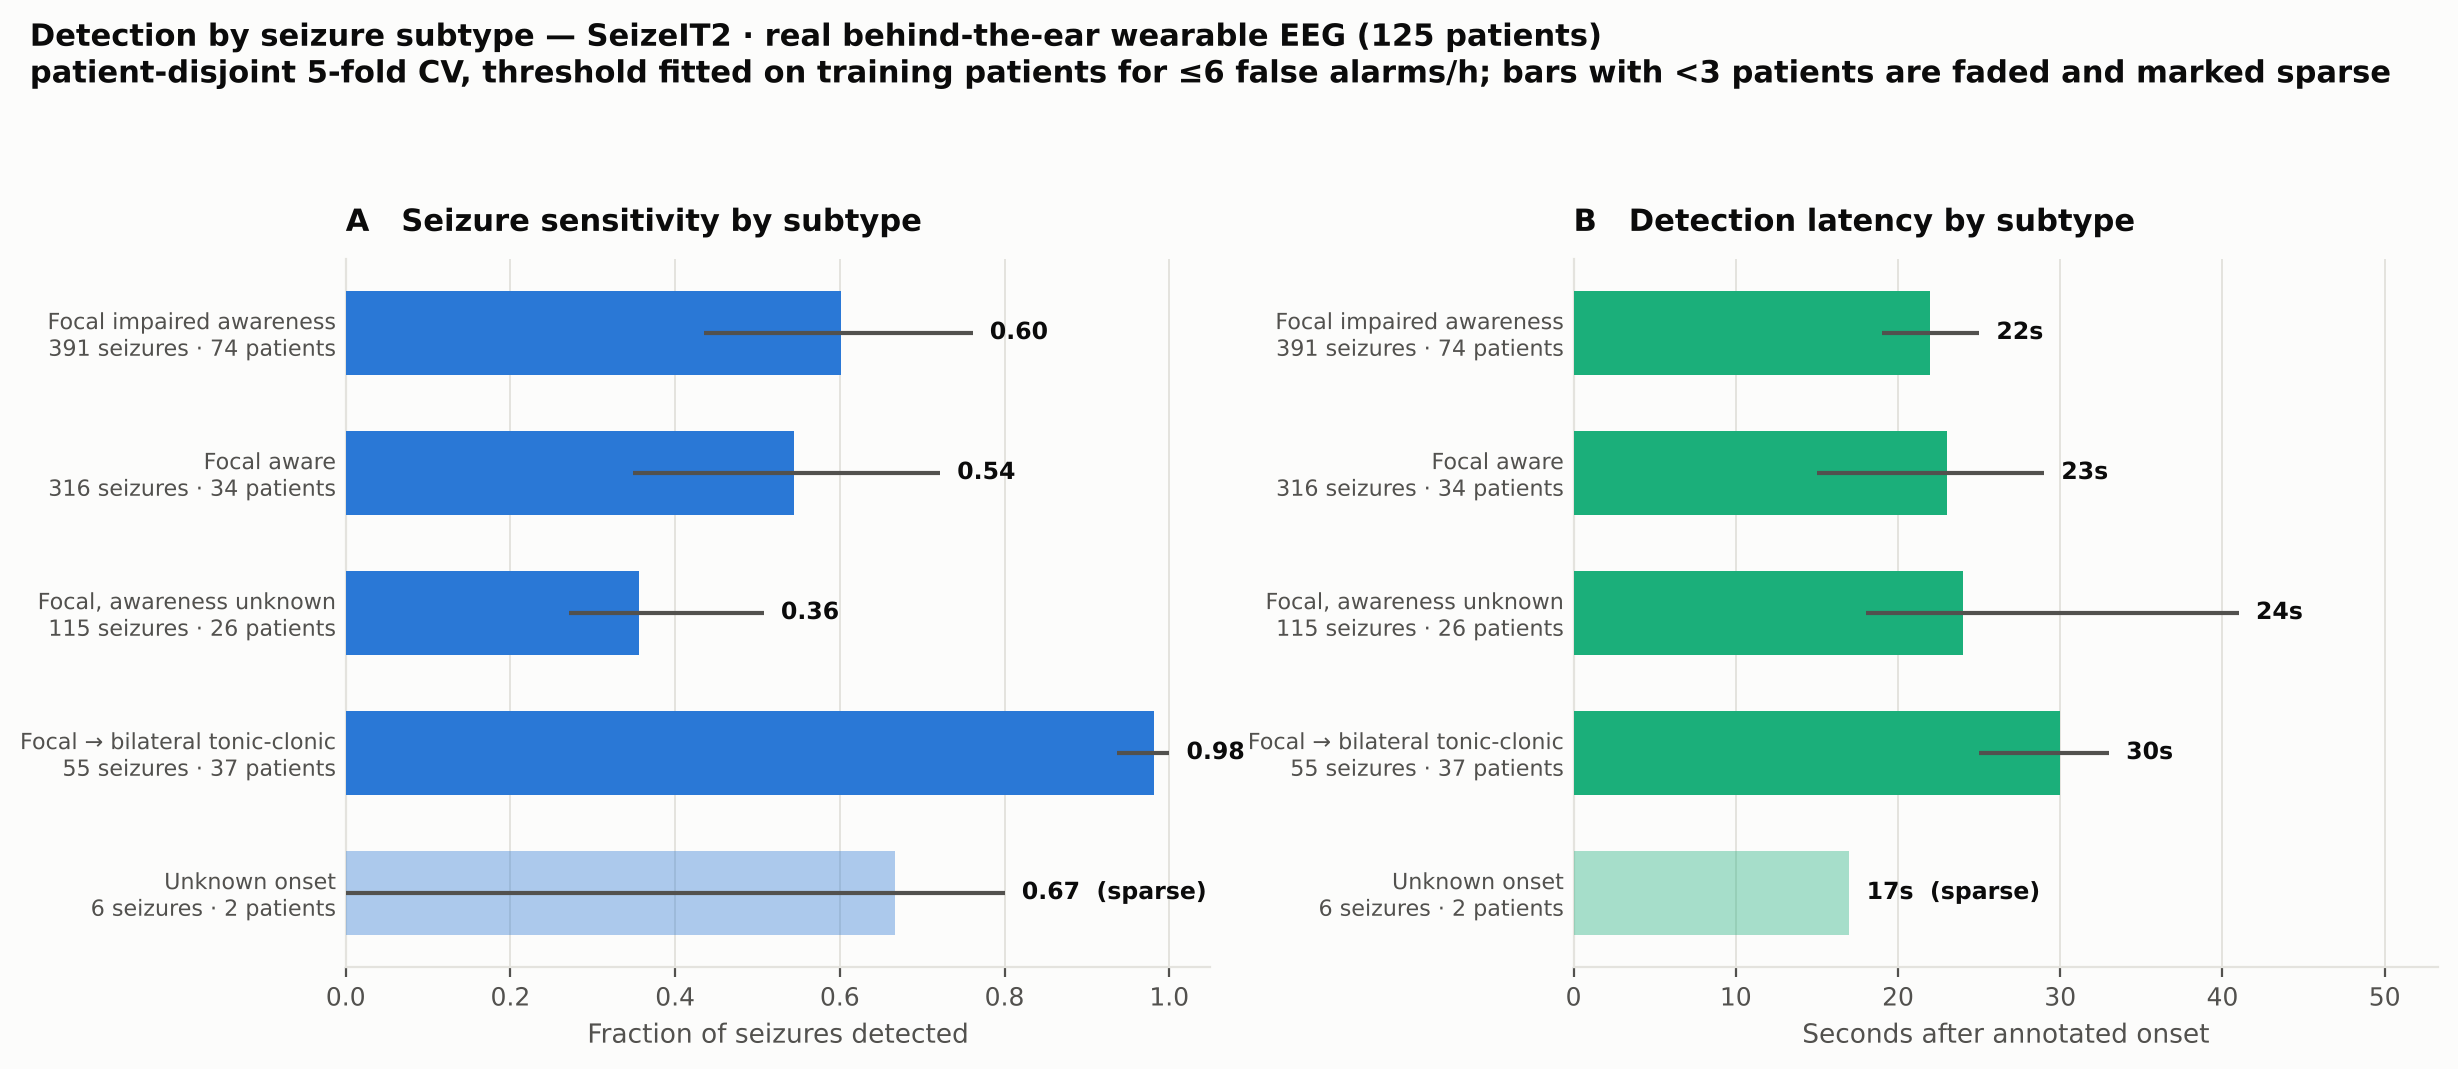

In [16]:
folds2 = pd.read_csv(TABLES_DIR / "seizeit2_cv_folds.csv")
out2 = pd.read_csv(TABLES_DIR / "seizeit2_event_outcomes.csv")
m6 = out2[out2.target_fa_per_h == 6.0]
f6 = folds2[folds2.target_fa_per_h == 6.0]
print(f"{int(m6.detected.sum())}/{len(m6)} seizures detected "
      f"({m6.detected.mean():.1%}) at the 6 FA/h target; "
      f"median latency {m6.loc[m6.detected,'latency_s'].median():.0f} s; "
      f"mean AUPRC {f6.auprc.mean():.3f} (prevalence {f6.prevalence.mean():.4f})")
display(pd.read_csv(TABLES_DIR / "seizeit2_subgroup_seizure_type.csv")
        .drop(columns=["dataset"], errors="ignore").round(3))
display(Image(filename=str(FIGURES_DIR / "fig5_seizeit2_subtype.png")))

## 11. Anatomical onset — exploratory

> The behind-the-ear sensors were positioned with reference to each patient's
> suspected onset zone, so anatomy and electrode placement are confounded.
> Read every row here as hypothesis-generating.

,target_fa_per_h,onset_lobe,n_seizures,n_patients,n_detected,sensitivity,sensitivity_lo,sensitivity_hi,median_latency_s,latency_lo,latency_hi,median_duration_s,n_detected_with_latency
0,6.0,temporal,264,68,181,0.686,0.571,0.791,24.0,22.000,28.0,60.5,181
1,6.0,unknown,231,36,87,0.377,0.254,0.728,23.0,18.488,25.0,13.0,87
2,6.0,multilobar,181,32,128,0.707,0.496,0.818,29.0,20.488,32.0,84.0,128
3,6.0,frontal,160,19,91,0.569,0.453,0.733,16.0,14.000,22.0,17.0,91
4,6.0,insular,18,2,3,0.167,0.071,0.500,21.0,10.500,29.0,14.5,3
5,6.0,occipital,17,5,10,0.588,0.333,0.923,25.0,19.000,89.0,81.0,10
6,6.0,central,11,1,5,0.455,NaN,NaN,24.0,NaN,NaN,7.0,5
7,6.0,parietal,1,1,1,1.000,NaN,NaN,52.0,NaN,NaN,134.0,1


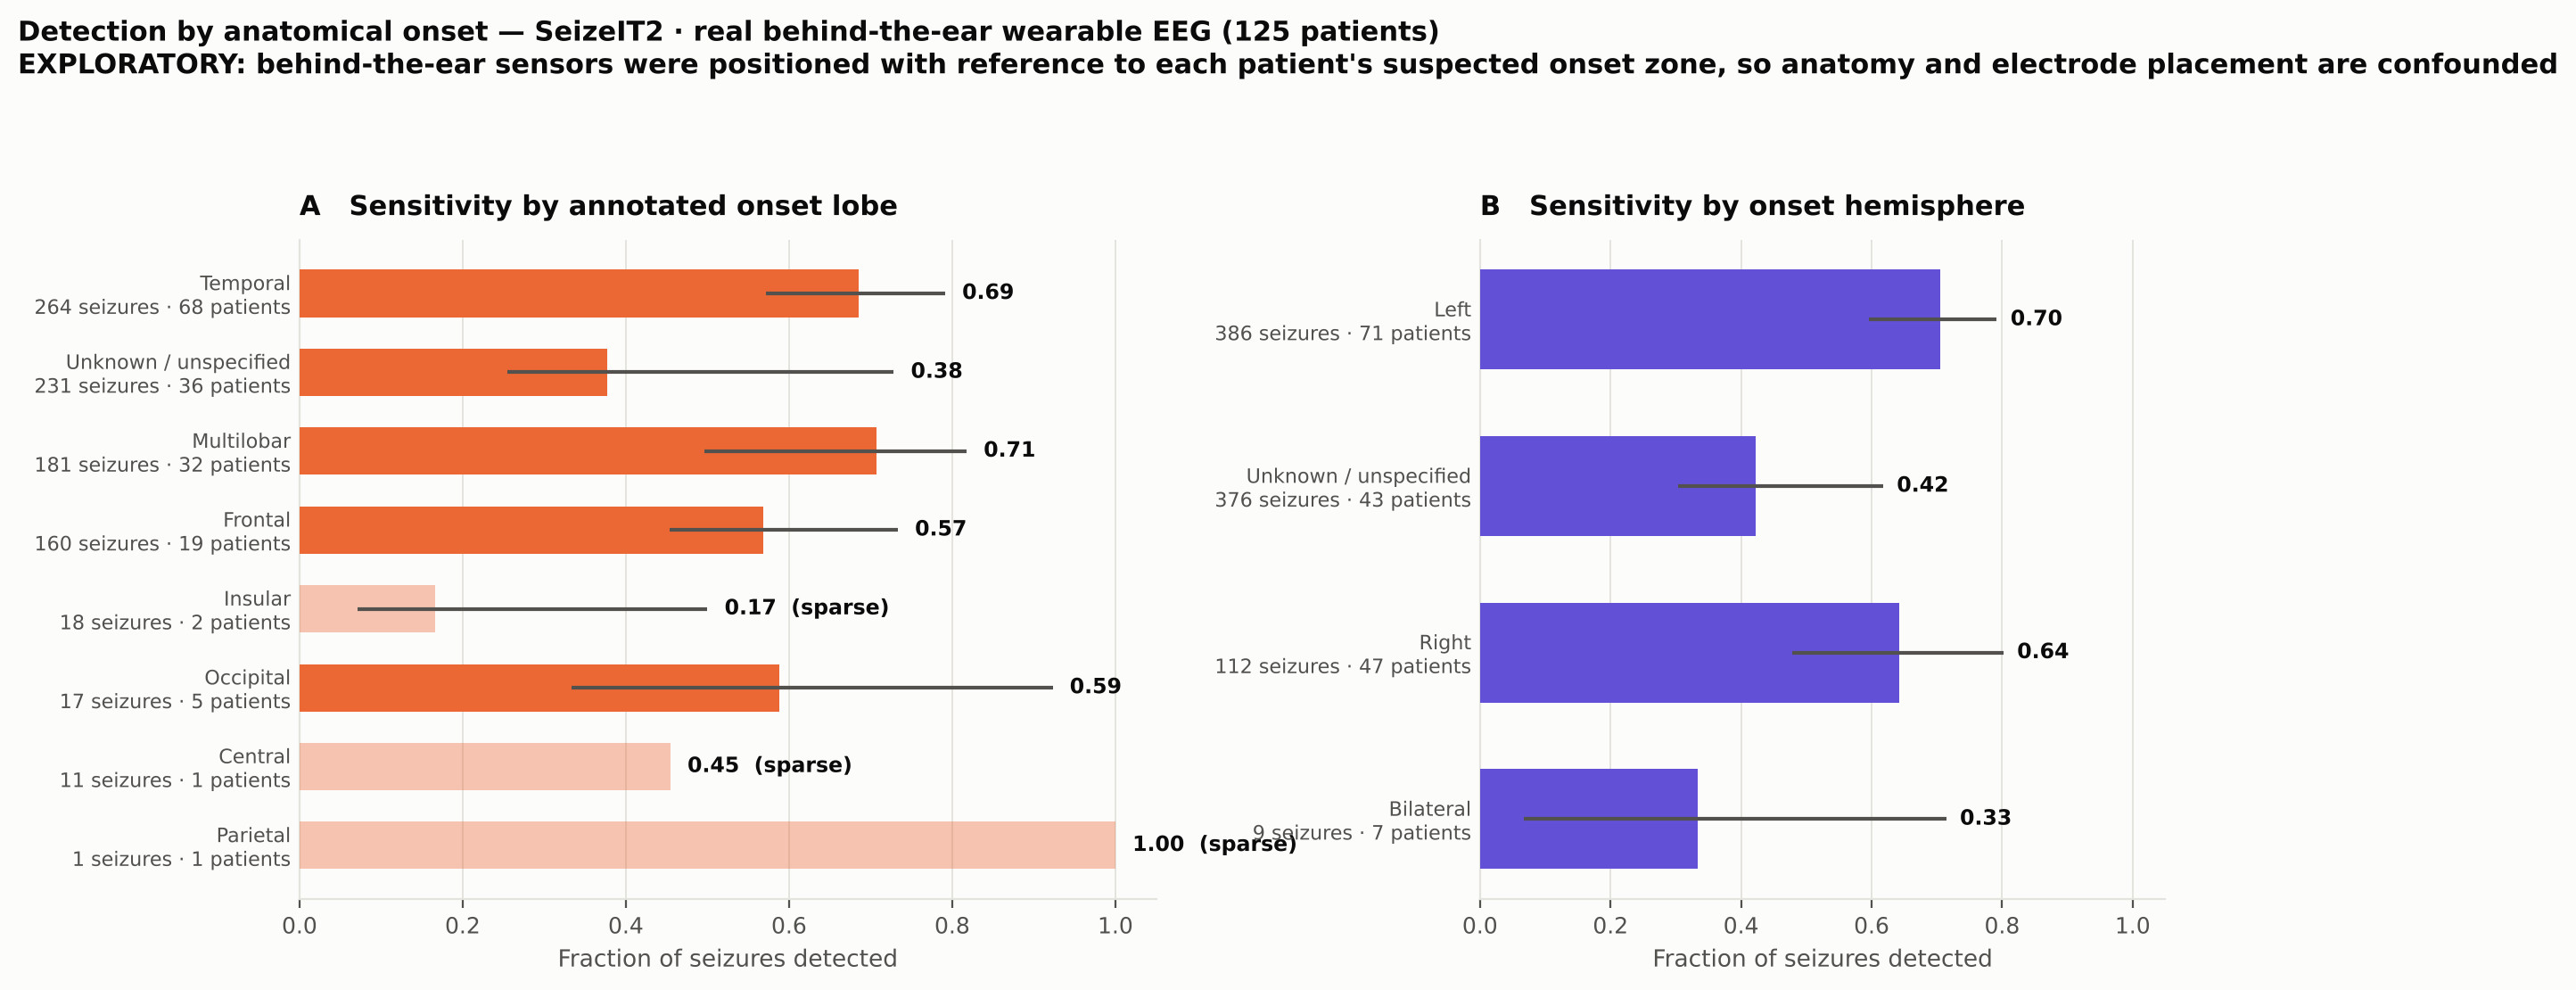

In [17]:
display(pd.read_csv(TABLES_DIR / "seizeit2_subgroup_onset_lobe.csv")
        .drop(columns=["dataset"], errors="ignore").round(3))
display(Image(filename=str(FIGURES_DIR / "fig6_seizeit2_onset_location.png")))

### Does the temporal-lobe hypothesis survive its confounds?

`involves_temporal == False` pools genuinely non-temporal onsets with seizures
whose localisation was never annotated. And focal-to-bilateral seizures are
detected almost perfectly, so they have to be excluded to separate the
anatomical question from the seizure-type one.

In [18]:
con = pd.read_csv(TABLES_DIR / "seizeit2_subgroup_contrasts.csv")
display(con[con.grouping.isin(["onset_lobe", "involves_temporal"])]
        [["grouping", "subset", "comparison", "n_seizures_a", "n_seizures_b",
          "sensitivity_a", "sensitivity_b", "delta", "ci_lo", "ci_hi"]]
        .round(3))

,grouping,subset,comparison,n_seizures_a,n_seizures_b,sensitivity_a,sensitivity_b,delta,ci_lo,ci_hi
0,onset_lobe,all seizures,temporal - frontal,264,160,0.686,0.569,0.117,-0.080,0.276
1,involves_temporal,all seizures,True - False,403,480,0.707,0.460,0.247,0.049,0.387
2,involves_temporal,localisation annotated only,True - False,403,249,0.707,0.538,0.169,0.002,0.295
3,involves_temporal,excluding focal-to-bilateral,True - False,376,452,0.689,0.427,0.262,0.058,0.404
4,involves_temporal,"localisation annotated, excluding focal-to-bil...",True - False,376,239,0.689,0.519,0.170,0.008,0.308
5,onset_lobe,"localisation annotated, excluding focal-to-bil...",temporal - frontal,247,155,0.668,0.555,0.113,-0.102,0.285


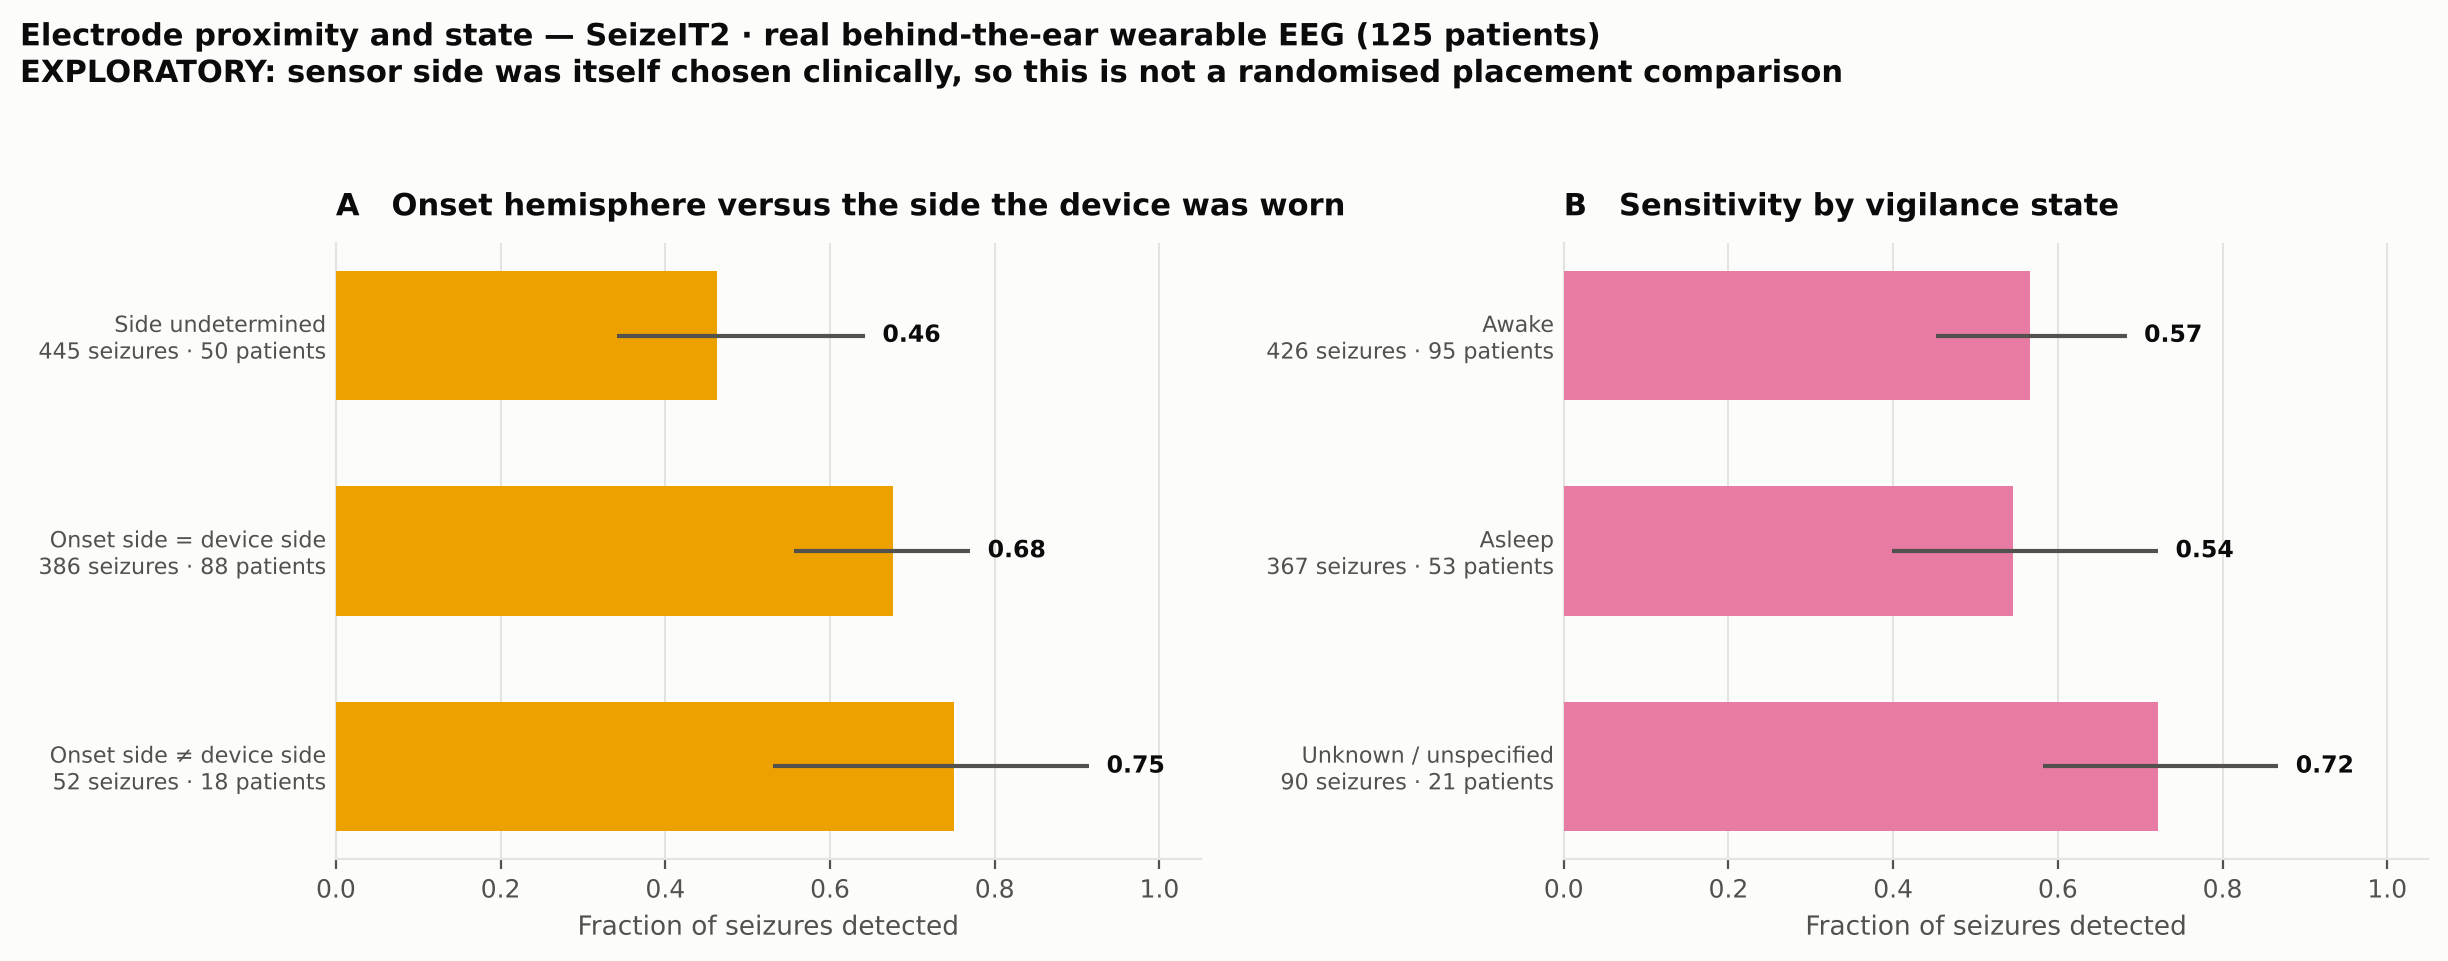

,grouping,subset,comparison,n_seizures_a,n_seizures_b,sensitivity_a,sensitivity_b,delta,ci_lo,ci_hi
6,onset_vs_device,all seizures,ipsilateral - contralateral,386,52,0.676,0.750,-0.074,-0.265,0.163
7,onset_vs_device,excluding focal-to-bilateral,ipsilateral - contralateral,359,45,0.652,0.733,-0.082,-0.301,0.206
8,vigilance,all seizures,asleep - awake,367,426,0.545,0.566,-0.021,-0.145,0.122
9,seizure_type,all seizures,focal_to_bilateral_tonic_clonic - focal_aware,55,316,0.982,0.544,0.438,0.266,0.641


In [19]:
display(Image(filename=str(FIGURES_DIR / "fig7_seizeit2_proximity_vigilance.png")))
display(con[con.grouping.isin(["onset_vs_device", "vigilance", "seizure_type"])]
        [["grouping", "subset", "comparison", "n_seizures_a", "n_seizures_b",
          "sensitivity_a", "sensitivity_b", "delta", "ci_lo", "ci_hi"]]
        .round(3))

## 12. TUH (TUSZ) — prepared, not run

The adapter is a skeleton and refuses to produce results until a real corpus is
mounted, so no TUH number can appear by accident.

In [20]:
print("TUSZAdapter.IMPLEMENTED =", TUSZAdapter.IMPLEMENTED)
try:
    adapters["TUSZ (planned)"].recordings()
except NotImplementedError as exc:
    print("\nrecordings() refuses:\n ", str(exc)[:240], "...")
display(Markdown("**Seizure-code mapping plan**"))
display(mapping_plan_frame())

TUSZAdapter.IMPLEMENTED = False

recordings() refuses:
  The TUSZ adapter is a skeleton. TUSZ requires a signed data-use agreement (https://isip.piconepress.com/projects/nedc/) and is not bundled here. Implement parsing of the term-based annotation files against the _DOCS of the exact corpus vers ...


**Seizure-code mapping plan**

,tusz_code,harmonised_type,included_as_seizure
0,fnsz,focal_unspecified,True
1,spsz,focal_aware,True
2,cpsz,focal_impaired_awareness,True
3,gnsz,generalized,True
4,absz,generalized,True
5,tnsz,generalized,True
6,cnsz,generalized,True
7,atsz,generalized,True
8,mysz,generalized,True
9,tcsz,unclassified,True


### Two rules that must survive TUH integration

1. **A seizure-type code is not an anatomical onset label.** `cpsz` means focal
   with impaired awareness; it says nothing about which lobe.
2. **Channel-level annotations are not localisation.** TUSZ marks which
   channels an event was seen on — an electrographic field shaped by montage
   and propagation, not a validated onset lobe.

The planned TUSZ analysis is the one neither corpus here can do: **does the gap
between full-scalp and wearable-inspired configurations depend on seizure
type?** TUSZ is the only one of the three with both full-scalp EEG and clinical
seizure-type codes.

The full write-up, with every number regenerated from the result tables, is in
`REPORT.md`.